<a href="https://colab.research.google.com/github/R-code11/colab-notebooks-python/blob/main/sessions/session-6/Python_Session_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Session 6**

## Basic EDA (Exploratory Data Analysis)

In Session 5 we loaded the data and looked at its structure.
Today we do **EDA** step by step. EDA simply means **exploring the data to understand it** before doing anything else.

## Part 1: Load the Data

Same as Session 5: connect Google Drive and read the file.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!ls "/content/drive/MyDrive/Colab Notebooks/Data/"

import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Data/academic_data.csv")

Mounted at /content/drive
academic_data.csv


In [22]:
import matplotlib.pyplot as plt

We already imported `pandas` above. We also import `matplotlib` because we need it for graphs (we used it in Session 5 too).

In [2]:
df.head()

,student_id,name,gender,age,year,section,study_hours,attendance,ai_usage_hours,ai_tool,marks,grade,complaint,complaint_type
0,STU1001,Dev Chopra,Male,19,3,A,9.1,61.3,11.7,Copilot,40.0,D,No,-
1,STU1002,Rohan Shah,Male,19,2,B,8.1,66.1,6.7,Copilot,38.8,F,No,-
2,STU1003,Ayaan Kapoor,Male,20,3,B,18.2,88.5,8.9,Claude,92.0,A,No,-
3,STU1004,Ishaan Rao,Male,21,4,A,20.6,82.5,11.3,Copilot,82.8,B,No,-
4,STU1005,Kabir Bose,Male,18,1,B,10.2,78.0,0.3,NaN,66.2,C,No,-


In [3]:
print(df.shape)

(100, 14)


**Quick reminder:** `df.shape` gives (number of rows, number of columns). Our data has **100 students** and **14 columns**.

## Part 2: Check Missing Values

Missing value means an **empty cell**. Before analysing anything, we should know where the data is empty.

In [4]:
df.isnull().sum()

,0
student_id,0
name,0
gender,0
age,0
year,0
section,0
study_hours,0
attendance,0
ai_usage_hours,0
ai_tool,7


**Explanation**

- `df.isnull()` checks every cell. It gives `True` if the cell is empty and `False` if it is filled.
- `.sum()` counts the `True` values in each column.

**Result:** only `ai_tool` has missing values (7 students). All other columns are complete. This is the same thing we saw in `df.info()` in Session 5.

### Fill the empty values

We will write `"No Tool"` in the empty cells. We make a **copy** of the data first, so the original `df` stays safe.

In [8]:
df_clean = df.copy()

df_clean["ai_tool"] = df_clean["ai_tool"].fillna("No Tool")

df_clean.isnull().sum()

,0
student_id,0
name,0
gender,0
age,0
year,0
section,0
study_hours,0
attendance,0
ai_usage_hours,0
ai_tool,0


**Explanation**

- `df.copy()` makes a copy of the table. We will do our work on `df_clean`.
- `fillna("No Tool")` fills every empty cell with the text `No Tool`.
- Now `isnull().sum()` shows 0 everywhere.

## Part 3: Categorical and Continuous Variables

A **variable** is just a column. There are two main types.

| Type | Meaning | Examples in our data |
|---|---|---|
| **Categorical** | Groups or labels. We **count** them. | `gender`, `section`, `year`, `ai_tool`, `grade`, `complaint_type` |
| **Continuous** | Numbers we can measure. We can take **average** of them. | `age`, `study_hours`, `attendance`, `ai_usage_hours`, `marks` |

### Easy trick to decide

- Does it make sense to calculate an **average**? Then it is **Continuous**.
- Is it a **group or label**? Then it is **Categorical**.

### Special case: `year`

`year` has numbers 1, 2, 3, 4, but these are groups (1st year, 2nd year...). Average of year makes no sense. So `year` is **Categorical**.

`student_id` and `name` are just identity columns. We do not analyse them.

In [9]:
categorical_cols = ["gender", "section", "year", "ai_tool", "grade", "complaint_type"]
continuous_cols  = ["age", "study_hours", "attendance", "ai_usage_hours", "marks"]

print("Categorical:", categorical_cols)
print("Continuous :", continuous_cols)

Categorical: ['gender', 'section', 'year', 'ai_tool', 'grade', 'complaint_type']
Continuous : ['age', 'study_hours', 'attendance', 'ai_usage_hours', 'marks']


:**Explanation:** We store the column names in two lists. Now we can use them again and again without typing the names.

## Part 4: Summary Statistics of Continuous Variables

Summary statistics means **describing a whole column with a few numbers**.

| Statistic | Meaning in simple words | Code |
|---|---|---|
| **mean** | Average | `.mean()` |
| **median** | Middle value after sorting | `.median()` |
| **min** | Smallest value | `.min()` |
| **max** | Largest value | `.max()` |
| **std** | How much the values are spread around the average | `.std()` |

### Step 1: One column, one statistic

Let us take `marks`.

In [10]:
print("Average marks :", df_clean["marks"].mean())
print("Middle marks  :", df_clean["marks"].median())
print("Lowest marks  :", df_clean["marks"].min())
print("Highest marks :", df_clean["marks"].max())
print("Spread (std)  :", df_clean["marks"].std())

Average marks : 69.179
Middle marks  : 69.3
Lowest marks  : 34.4
Highest marks : 100.0
Spread (std)  : 17.758920336415486


**Explanation**

- `df_clean["marks"]` selects the one column.
- Then we add the statistic we want, like `.mean()`.
- **Mean vs Median:** if both are close, the data is balanced. If they are very different, a few very big or very small values are pulling the average.

### Step 2: All continuous columns at once

Instead of doing it one by one, we can ask for the statistic of **all continuous columns together**.

In [11]:
df_clean[continuous_cols].mean()

,0
age,19.430
study_hours,15.011
attendance,79.296
ai_usage_hours,7.220
marks,69.179


In [12]:
df_clean[continuous_cols].max()

,0
age,22.0
study_hours,26.1
attendance,100.0
ai_usage_hours,14.4
marks,100.0


**Explanation:** `df_clean[continuous_cols]` selects all five continuous columns. Then the statistic is calculated for each one.

### Step 3: `describe()` gives everything in one shot

You already used this in Session 5.

In [13]:
df_clean[continuous_cols].describe()

,age,study_hours,attendance,ai_usage_hours,marks
count,100.00000,100.000000,100.000000,100.000000,100.00000
mean,19.43000,15.011000,79.296000,7.220000,69.17900
std,1.26535,4.606493,10.706601,3.232224,17.75892
min,17.00000,6.700000,59.300000,0.100000,34.40000
25%,19.00000,10.900000,69.550000,4.775000,52.67500
50%,20.00000,15.350000,81.000000,7.150000,69.30000
75%,20.00000,18.700000,87.075000,9.425000,83.37500
max,22.00000,26.100000,100.000000,14.400000,100.00000


**How to read it**

| Row | Meaning |
|---|---|
| `count` | Number of filled values |
| `mean` | Average |
| `std` | Spread |
| `min` | Smallest value |
| `25%` | 25 out of 100 students are below this value |
| `50%` | Median. Half of the students are below this value |
| `75%` | 75 out of 100 students are below this value |
| `max` | Largest value |

**Example:** look at the `marks` column. The average is about 69, the lowest is about 34 and the highest is 100. Half of the students got less than about 69 marks.

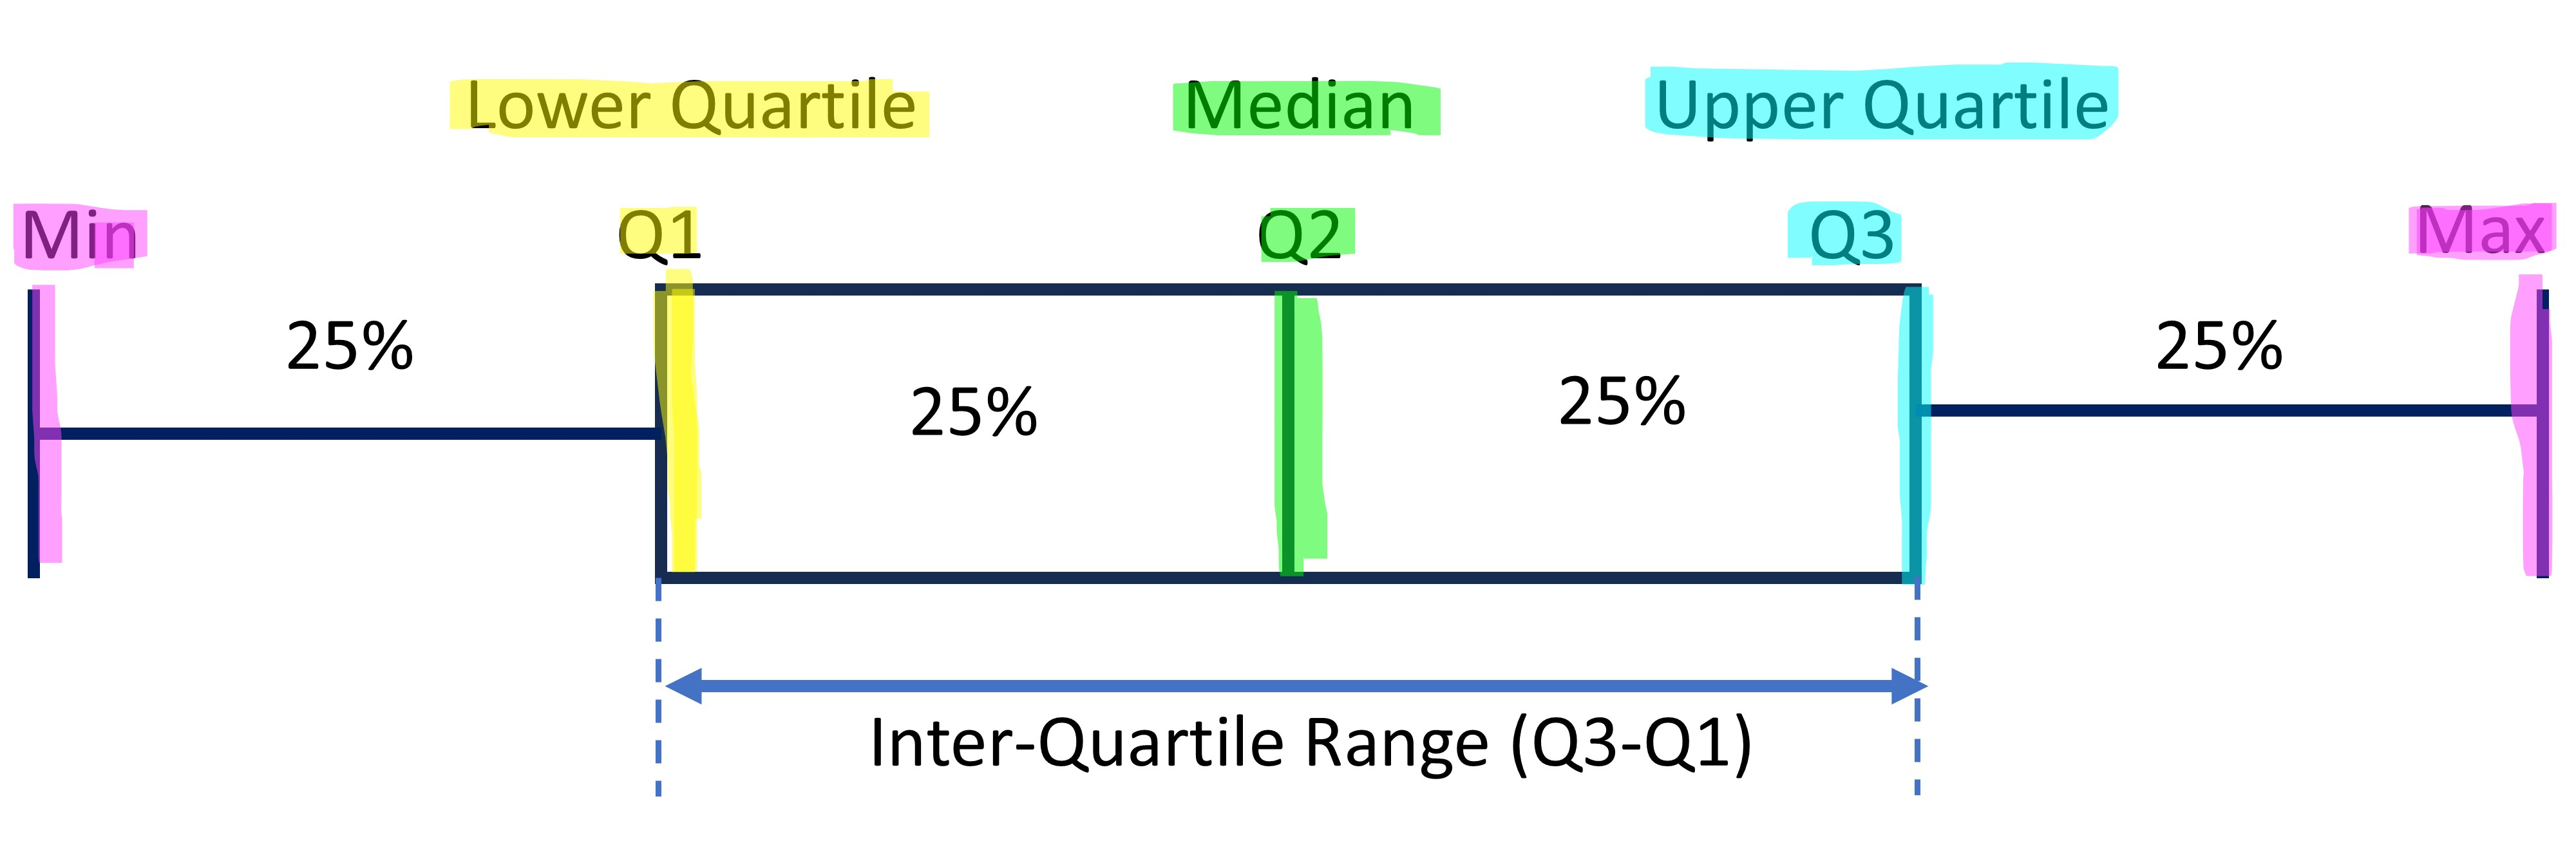

## Part 4: Summary Statistics of Categorical Variables

For categories, mean and median do not make sense. We only **count** how many students are in each category.

In [ ]:
df_clean["section"].value_counts()

In [ ]:
df_clean["grade"].value_counts()

###  All categorical columns in one loop

we use a **for loop**.

In [18]:
for col in categorical_cols:
    print("---", col, "---")
    print(df_clean[col].value_counts())
    print()

--- gender ---
gender
Male      60
Female    40
Name: count, dtype: int64

--- section ---
section
A    37
B    36
C    27
Name: count, dtype: int64

--- year ---
year
2    32
3    30
4    21
1    17
Name: count, dtype: int64

--- ai_tool ---
ai_tool
Gemini      27
ChatGPT     22
Multiple    17
Copilot     14
Claude      13
No Tool      7
Name: count, dtype: int64

--- grade ---
grade
D    26
B    25
A    23
C    23
F     3
Name: count, dtype: int64

--- complaint_type ---
complaint_type
-                 91
AI misuse          4
Low attendance     3
Discipline         2
Name: count, dtype: int64



**Explanation**

- `for col in categorical_cols:` means: take one column name at a time from the list and run the indented lines for it.
- `print(df_clean[col].value_counts())` prints the counts for that column.
- We use `print()` here because inside a loop, only `print` shows every result.

## PART 5 : Graphs for One Variable

Numbers are good, but graphs show the picture quickly.

| Variable type | Graph we use |
|---|---|
| Continuous | Histogram, Boxplot |
| Categorical | Bar chart, Pie chart |

### 5.1 Histogram (for Continuous)

A histogram shows **how many students fall in each range of values**. For example, how many students got 40 to 50 marks, 50 to 60 marks and so on.

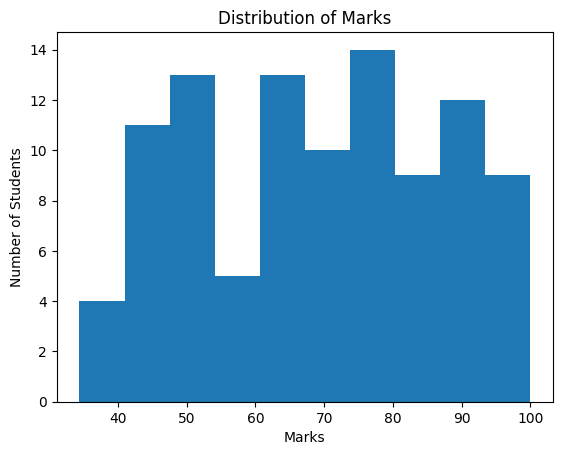

In [23]:
df_clean["marks"].plot(kind="hist", bins=10)
plt.title("Distribution of Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.show()

**Explanation**

- `kind="hist"` means histogram.
- `bins=10` means the range is divided into 10 groups (bars). Try `bins=5` and `bins=20` and see what changes.
- `plt.title()`, `plt.xlabel()`, `plt.ylabel()` add the title and the axis names.
- The **taller** the bar, the **more** students are in that range.

### 5.2 Boxplot (for Continuous)

A boxplot shows the **minimum, 25%, median, 75% and maximum** in one picture.

| Part of the box | Meaning |
|---|---|
| Line inside the box | Median |
| Bottom of the box | 25% value |
| Top of the box | 75% value |
| Lines (whiskers) | Smallest and largest normal values |
| Dots outside | Very unusual values (called **outliers**) |

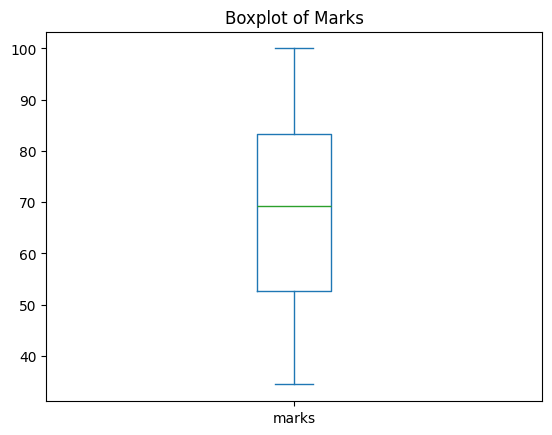

In [24]:
df_clean["marks"].plot(kind="box")
plt.title("Boxplot of Marks")
plt.show()

**Explanation:** The box contains the middle 50 percent of the students. If you see dots far away from the box, those students are very different from the rest.

### 5.3 Bar Chart (for Categorical)

A bar chart shows the **count of each category**. We first calculate `value_counts()` and then plot it.

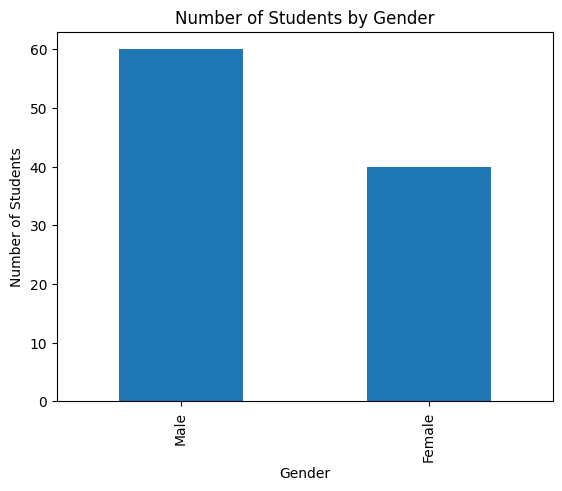

In [26]:
df_clean["gender"].value_counts().plot(kind="bar")
plt.title("Number of Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.show()

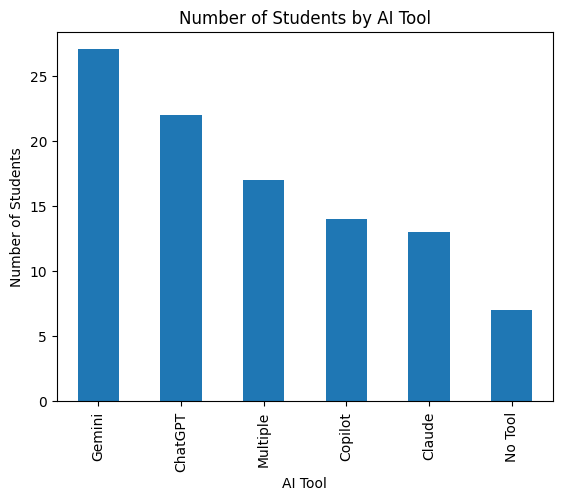

In [27]:
df_clean["ai_tool"].value_counts().plot(kind="bar")
plt.title("Number of Students by AI Tool")
plt.xlabel("AI Tool")
plt.ylabel("Number of Students")
plt.show()

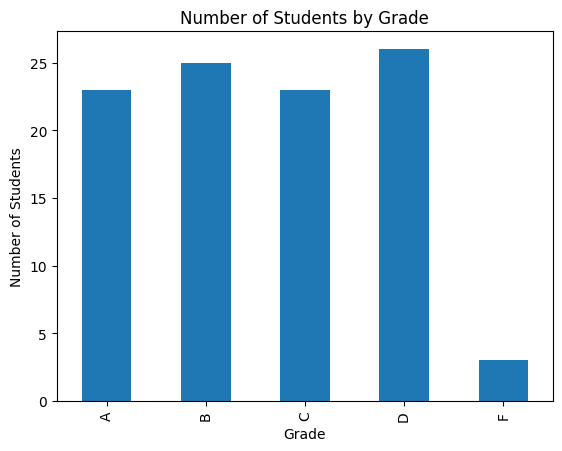

In [28]:
df_clean["grade"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Students by Grade")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.show()

**Explanation**

- `value_counts()` counts the students in each category, and `.plot(kind="bar")` draws the bars.
- `sort_index()` arranges the bars in the order A, B, C, D, F. Without it, bars are arranged from the biggest to the smallest.

### 5.4 Pie Chart (for Categorical)

A pie chart shows each category as a **part of the whole**. Use it only when there are very few categories.

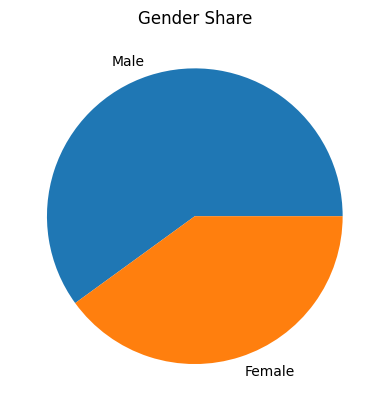

In [30]:
df_clean["gender"].value_counts().plot(kind="pie")
plt.title("Gender Share")
plt.ylabel("")
plt.show()

**Explanation**

- `kind="pie"` draws a pie chart.
- `plt.ylabel("")` removes the extra label pandas adds on the side.

## Part 6: Relationship Between Two Variables

Now we check whether **two variables are connected**. For example: do students who study more get more marks?

| Two variables | What we use |
|---|---|
| Continuous and Continuous | Scatter plot and correlation |
| Categorical and Continuous | `groupby` and average |
| Categorical and Categorical | `crosstab` |

### 6.1 Continuous and Continuous

#### Scatter plot

We did this in Session 5.

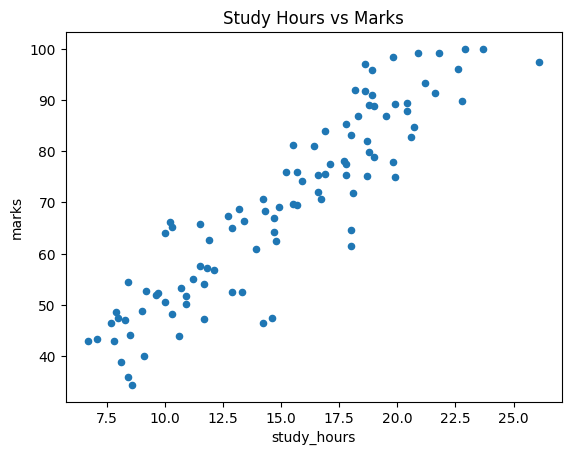

In [31]:
df_clean.plot(kind="scatter", x="study_hours", y="marks")
plt.title("Study Hours vs Marks")
plt.show()

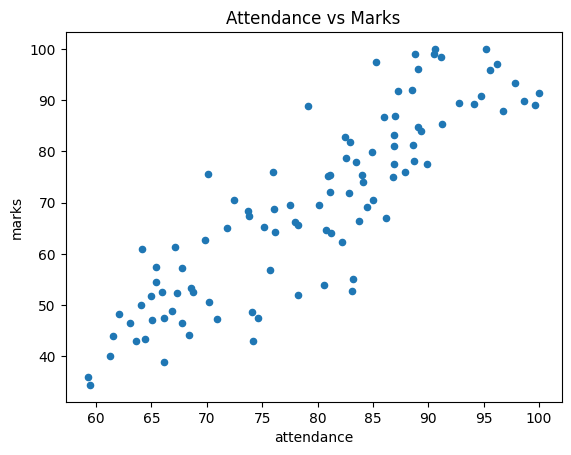

In [32]:
df_clean.plot(kind="scatter", x="attendance", y="marks")
plt.title("Attendance vs Marks")
plt.show()

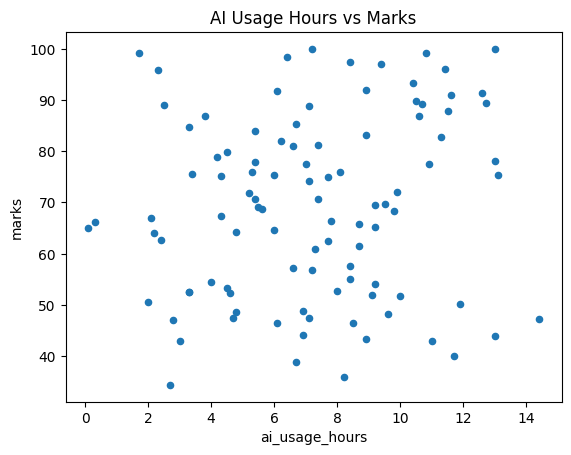

In [33]:
df_clean.plot(kind="scatter", x="ai_usage_hours", y="marks")
plt.title("AI Usage Hours vs Marks")
plt.show()

**How to read a scatter plot**

- Dots going **upwards** (left to right): when one increases, the other also increases.
- Dots going **downwards**: when one increases, the other decreases.
- Dots **scattered everywhere** with no direction: no clear relationship.

### 7.2 Categorical and Continuous

Here we compare a number across groups. For example: **average marks of males and females**.
We use `groupby`.

In [36]:
df_clean.groupby("gender")["marks"].mean()

,marks
gender,
Female,70.070
Male,68.585


**Explanation**

- `groupby("gender")` makes one group for each gender.
- `["marks"]` selects the column we want to calculate.
- `.mean()` calculates the average for each group.

Read it as: *for each gender, what is the average marks?*

In [38]:
df_clean.groupby("grade")["marks"].mean()

,marks
grade,
A,92.860870
B,77.448000
C,64.130435
D,48.526923
F,36.400000


**Explanation:** The grade table is a good check. Students with grade A should have the highest average marks. If not, something is wrong with the data.

## Practice Questions

Try these yourself. Use the same code from today and change the column names.

**Easy**

1. Find the average, minimum and maximum of `attendance`.
2. Count students in each `year`.
3. Draw a histogram of `ai_usage_hours`.

**Medium**

4. Find the average `study_hours` for each `grade`.
5. Draw a bar chart of the number of students in each `section`.

**Challenging**

6. How many students have `study_hours` greater than 20?
7. Find the average `marks` of students who made a complaint and those who did not.
8. Draw a scatter plot of `attendance` vs `study_hours`. Do you see any pattern?